# **Mejora 2: Atención espacial con CBAM sobre *Spatial Bottleneck***

## **0. Introducción y objetivo**

Partimos como **baseline** de `mejora1.ipynb`, donde sustituimos las capas densas del cuello de botella por una convolución $1 \times 1$ para mantener un espacio latente espacial de forma `(4, 4, 16)` (`256` valores totales). El siguiente paso dentro del **Bloque 2** de `explicacion_mejoras.ipynb` (punto **2.2**) es incorporar **mecanismos de atención espacial**, ya que las convoluciones locales $3 \times 3$ y $4 \times 4$ tienen un campo receptivo limitado y no coordinan bien qué zonas de la imagen importan más o cómo se relacionan rasgos distantes.

Existen dos enfoques principales para nuestro autoencoder de `64x64`: **CBAM** (*Convolutional Block Attention Module*) y **Self-Attention** (estilo Transformer). En este notebook comparamos ambos enfoques para justificar por qué los dos tienen sentido, implementamos **CBAM** en `mejora2.ipynb` y dejamos **Self-Attention** para `mejora3.ipynb`, manteniendo en ambos el mismo baseline de `mejora1.ipynb`.

### **Por qué tienen sentido CBAM y Self-Attention y en qué se diferencian**

La diferencia principal está en **cómo procesan la información espacial**: **Self-Attention** calcula *relaciones entre pares de regiones* (un grafo completo), mientras que **CBAM** calcula *una máscara de importancia* (un filtro local).

| Criterio | Self-Attention (estilo Transformer) | CBAM (Convolutional Block Attention) |
| --- | --- | --- |
| **Operación central** | Producto escalar entre *Queries*, *Keys* y *Values* ($Q K^T V$). | *Pooling* global de canales + convolución $7 \times 7$ con `sigmoid`. |
| **Comunicación espacial** | **Global (todos con todos):** cualquier celda conecta directamente con cualquier otra en 1 paso. | **Local:** sigue limitado al tamaño del kernel ($7 \times 7$); no conecta extremos opuestos. |
| **Qué aprende realmente** | *"Si aquí hay patilla de gafa izquierda, al otro lado debe haber patilla derecha"*. | *"El centro de la imagen es rostro (peso 0.9); las esquinas son fondo (peso 0.1)"*. |
| **Coste de memoria y tiempo** | Escala cuadráticamente con los píxeles: $O((H \cdot W)^2)$. Viable en $8 \times 8$, pesado en $32 \times 32$. | Lineal y despreciable: $O(H \cdot W)$. Viable en todas las capas ($32 \times 32$, $16 \times 16$, $8 \times 8$). |
| **Parámetros extra** | Moderados (proyecciones lineales $W_q, W_k, W_v, W_o$). | Mínimos (dos capas densas pequeñas y una `Conv2D` de 1 filtro). |
| **Estabilidad en 30 épocas** | Requiere un parámetro escalar $\gamma$ inicializado en `0`. | Muy estable; converge sin ajustes especiales. |

1. **Cómo ven una cara:**
   - **Self-Attention funciona por correspondencia:** divide el mapa de $8 \times 8$ en `64` celdas y crea una matriz de atención de $64 \times 64$. Si una celda detecta el brillo de un pendiente o el borde de una gafa, busca activamente en toda la imagen qué otra celda es compatible. Es mejor para **mantener la simetría facial o coherencia** durante una interpolación.
   - **CBAM funciona por relevancia:** no sabe que el ojo izquierdo y el derecho son pareja. Mira todos los filtros del bloque convolucional para apagar canales irrelevantes (por ejemplo, texturas de fondo) y genera un mapa 2D que atenúa las zonas con poca información (pared lisa detrás de la cabeza) y resalta los rasgos con detalle (ojos, nariz, boca).

2. **Coste y estabilidad en nuestro entrenamiento:**
   - Añadir **CBAM** en $16 \times 16$ y $8 \times 8$ apenas varía el tiempo por época (~1–2 %) y no introduce riesgo de inestabilidad en `30` épocas con *Cosine Decay*.
   - Añadir **Self-Attention** en $8 \times 8$ también es rápido (una matriz $64 \times 64$ es pequeña), pero no conviene ponerlo en $32 \times 32$ o $64 \times 64$ (matrices de $1024 \times 1024$ o $4096 \times 4096$) y necesita inicializar $\gamma = 0$ en $y = \gamma \cdot \text{Attention}(x) + x$ para evitar problemas en las primeras épocas.

### **Por qué empezamos con CBAM aquí**

- **CBAM** es la mejora más segura y ligera cuando los fondos variados de CelebA usan capacidad del latente de `256` valores y provocan caras borrosas.
- En **`mejora3.ipynb`** aplicaremos **Self-Attention en $8 \times 8$** y $16 \times 16$** sobre el mismo baseline (`mejora1`) para comprobar si la simetría global mejora aún más el morphing. Como actúan en escalas distintas, tampoco son excluyentes: podríamos combinar CBAM en $16 \times 16$ con Self-Attention en $8 \times 8$, aunque por falta de cómputo no lo haremos. Además, hicimos una pequeña prueba que no ha sido incluida por claridad y que no mejoraba los resultados, lo que significa que metodologías tan complejas con resoluciones tan bajas no aportan beneficios significativos.

Trabajamos de forma **determinista en la medida permitida por el entorno**, con `TRAIN_MODEL = True` para el primer entrenamiento (cambiar a `False` tras guardar los checkpoints).

---

## **1. Configuración e imports**

Importamos las mismas bibliotecas que en `mejora1.ipynb` y resolvemos las rutas desde `mejoras_autoencoders/`. Mantenemos todos los hiperparámetros del baseline (`LATENT_CHANNELS = 16` sobre `4x4`, `EPOCHS = 30`, `BATCH_SIZE = 128`, `SEED = 1234`) y guardamos los artefactos con el nombre `mejora2_spatial_cbam256`.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

from PIL import Image
from IPython.display import Image as IPyImage, display

In [2]:
SEED = 1234
IMG_SIZE = 64
CHANNELS = 3
# Experimento 2.2a (CBAM sobre Spatial Bottleneck): misma configuración que mejora1.
LATENT_CHANNELS = 16
LATENT_SHAPE = (4, 4, LATENT_CHANNELS)
LATENT_DIM = int(np.prod(LATENT_SHAPE))
BATCH_SIZE = 128
EPOCHS = 30

TRAIN_MODEL = True
NOTEBOOK_NAME = "mejora2_spatial_cbam256"

PROCESSED_DIR = Path("../data/processed")

# Verificar que están los 9 archivos requeridos
_required_data_files = tuple(
    Path(split) / filename
    for split in ("train", "val", "test")
    for filename in ("x.npy", "attrs.npy", "ids.npy")
)
if not all((PROCESSED_DIR / relative_path).is_file() for relative_path in _required_data_files):
    raise FileNotFoundError(f"Faltan algunos archivos en {PROCESSED_DIR.resolve()}")

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

AE_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}.keras"
ENCODER_PATH = CHECKPOINT_DIR / f"encoder_{NOTEBOOK_NAME}.keras"
DECODER_PATH = CHECKPOINT_DIR / f"decoder_{NOTEBOOK_NAME}.keras"
HISTORY_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_history.json"

np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"Datos localizados correctamente en: {PROCESSED_DIR.resolve()}")
print(f"Latente espacial: {LATENT_SHAPE} ({LATENT_DIM} valores totales)")

Datos localizados correctamente en: /Users/dani22/Desktop/ProyectoCD/morphing/data/processed
Latente espacial: (4, 4, 16) (256 valores totales)


In [3]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU detectada: {gpus}")
else:
    print("Corriendo en CPU.")

GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---

## **2. Carga de `train`, `val` y `test`**

Respetamos exactamente las particiones guardadas en `data/processed` para que la comparación con `mejora1.ipynb` sea justa. Convertimos las imágenes de `uint8 [0, 255]` a `float32 [0, 1]` porque la salida del decoder usa una sigmoide.

In [4]:
def load_split(name):
    split_dir = PROCESSED_DIR / name
    x = np.load(split_dir / "x.npy", allow_pickle=False)
    attrs = np.load(split_dir / "attrs.npy", allow_pickle=False)
    ids = np.load(split_dir / "ids.npy", allow_pickle=True)
    if x.ndim != 4 or x.shape[1:] != (IMG_SIZE, IMG_SIZE, CHANNELS):
        raise ValueError(f"{name}/x.npy tiene forma {x.shape}; se esperaba (N, 64, 64, 3)")
    if attrs.shape[0] != x.shape[0] or ids.shape[0] != x.shape[0]:
        raise ValueError(f"Los archivos de {name} no tienen el mismo número de ejemplos")
    return x.astype("float32") / 255.0, attrs, ids

x_train, attrs_train, ids_train = load_split("train")
x_val, attrs_val, ids_val = load_split("val")
x_test, attrs_test, ids_test = load_split("test")

print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}")
print(f"Rango train: [{x_train.min():.3f}, {x_train.max():.3f}]")

train: (60000, 64, 64, 3), val: (5000, 64, 64, 3), test: (10000, 64, 64, 3)
Rango train: [0.000, 1.000]


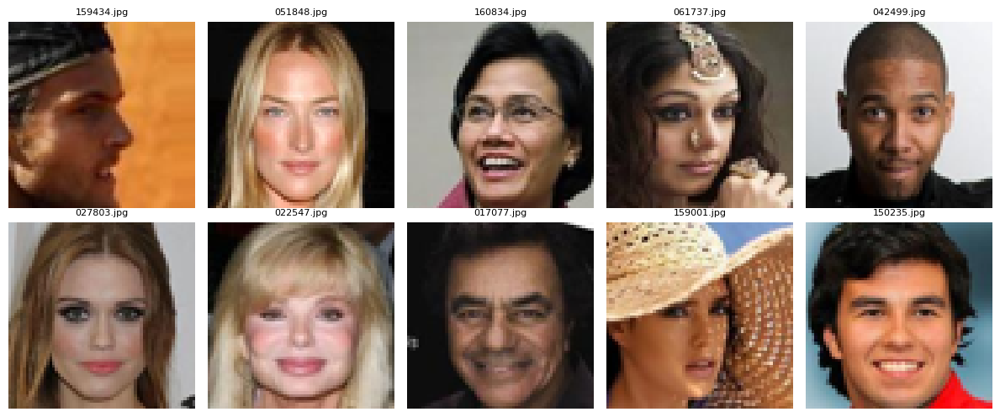

In [5]:
def show_images(images, titles=None, cols=5, figsize=(12, 8)):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, image, index in zip(axes.flat, images, range(len(images))):
        ax.imshow(np.clip(image, 0, 1))
        ax.axis("off")
        if titles is not None:
            ax.set_title(str(titles[index]), fontsize=8)
    for ax in axes.flat[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

sample_rng = np.random.default_rng(SEED)
sample_indices = sample_rng.choice(len(x_train), size=10, replace=False)
show_images(x_train[sample_indices], ids_train[sample_indices], cols=5, figsize=(12, 5))

---

## **3. Encoder, decoder y autoencoder con CBAM**

Mantenemos la arquitectura completa de `mejora1.ipynb` (incluyendo el cuello de botella `4x4x16` mediante convoluciones $1 \times 1$) y añadimos un bloque **CBAM** en las resoluciones **`16x16` y `8x8`** tanto en el encoder como en el decoder:

- **En el encoder:** tras el bloque `16x16` (`64` filtros) y tras el bloque `8x8` (`128` filtros), antes de comprimir a `4x4`.
- **En el decoder:** tras el bloque `8x8` (`256` filtros) y tras el bloque `16x16` (`128` filtros).

Cada bloque `CBAMBlock` aplica secuencialmente:
1. **Atención de canal:** resume cada mapa de características mediante *Global Average Pooling* y *Global Max Pooling*, los pasa por un MLP compartido con reducción `ratio=8`, los suma y aplica `sigmoid` para reponderar qué filtros son relevantes en esa imagen.
2. **Atención espacial:** calcula la media y el máximo a lo largo del eje de canales, los concatena (`2` mapas 2D) y aplica una `Conv2D(1, 7x7, activation="sigmoid")` para generar una máscara espacial que colapse el fondo y refuerce los rasgos faciales.

In [ ]:
@tf.keras.utils.register_keras_serializable(package="MejorasAE")
class CBAMBlock(layers.Layer):
    def __init__(self, ratio=8, kernel_size=7, **kwargs):
        super().__init__(**kwargs)
        self.ratio = ratio
        self.kernel_size = kernel_size

    def build(self, input_shape):
        channels = int(input_shape[-1])
        reduced = max(1, channels // self.ratio)
        self.shared_dense_1 = layers.Dense(reduced, activation="relu", use_bias=True)
        self.shared_dense_2 = layers.Dense(channels, use_bias=True)
        self.spatial_conv = layers.Conv2D(
            1,
            kernel_size=self.kernel_size,
            padding="same",
            activation="sigmoid",
            use_bias=False,
        )
        super().build(input_shape)

    def call(self, inputs):
        # Atención de canal
        avg_pool = tf.reduce_mean(inputs, axis=[1, 2], keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=[1, 2], keepdims=True)
        avg_out = self.shared_dense_2(self.shared_dense_1(avg_pool))
        max_out = self.shared_dense_2(self.shared_dense_1(max_pool))
        channel_attn = tf.nn.sigmoid(avg_out + max_out)
        x = inputs * channel_attn

        # Atención espacial
        spatial_avg = tf.reduce_mean(x, axis=-1, keepdims=True)
        spatial_max = tf.reduce_max(x, axis=-1, keepdims=True)
        concat = tf.concat([spatial_avg, spatial_max], axis=-1)
        spatial_attn = self.spatial_conv(concat)
        return x * spatial_attn

    def get_config(self):
        config = super().get_config()
        config.update({"ratio": self.ratio, "kernel_size": self.kernel_size})
        return config


encoder_inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="encoder_input")
x = encoder_inputs
for filters in (32, 64, 128, 256):
    x = layers.Conv2D(filters, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    if filters in (64, 128):  # resoluciones 16x16 y 8x8
        x = CBAMBlock(ratio=8, name=f"cbam_enc_{filters}")(x)

# Cuello de botella espacial: proyección 1x1 sobre 4x4x256 -> 4x4x16 (256 valores)
z = layers.Conv2D(
    LATENT_CHANNELS,
    kernel_size=1,
    padding="same",
    kernel_regularizer=keras.regularizers.l2(1e-5),
    name="latent_spatial",
)(x)
encoder_ae = keras.Model(encoder_inputs, z, name="encoder_ae")
encoder_ae.summary()

2026-11-16 22:31:30.960263: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-11-16 22:31:30.960300: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-11-16 22:31:30.960316: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
2026-11-16 22:31:30.960342: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-16 22:31:30.960362: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "encoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_enc_64 (CBAMBlock)         │ (None, 16, 16, 64)     │         1,194 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_enc_128 (CBAMBlock)        │ (None, 8, 8, 128)      │         4,338 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 256)      │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_spatial (Conv2D)         │ (None, 4, 4, 16)       │         4,112 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 701,228 (2.67 MB)

 Trainable params: 700,268 (2.67 MB)

 Non-trainable params: 960 (3.75 KB)

In [7]:
decoder_inputs = keras.Input(shape=LATENT_SHAPE, name="decoder_input")
x = layers.Conv2D(256, kernel_size=1, padding="same", use_bias=False)(decoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

for filters in (256, 128, 64, 32):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    if filters in (256, 128):  # resoluciones 8x8 y 16x16
        x = CBAMBlock(ratio=8, name=f"cbam_dec_{filters}")(x)

decoder_outputs = layers.Conv2D(
    CHANNELS, kernel_size=3, padding="same", activation="sigmoid", name="decoder_output"
)(x)
decoder_ae = keras.Model(decoder_inputs, decoder_outputs, name="decoder_ae")
decoder_ae.summary()

Model: "decoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 4, 4, 256)      │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_dec_256 (CBAMBlock)        │ (None, 8, 8, 256)      │        16,770 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 128)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_dec_128 (CBAMBlock)        │ (None, 16, 16, 128)    │         4,338 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 32, 32, 64)     │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 64, 64, 32)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,005,911 (3.84 MB)

 Trainable params: 1,004,439 (3.83 MB)

 Non-trainable params: 1,472 (5.75 KB)

In [8]:
autoencoder_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="autoencoder_input")
autoencoder = keras.Model(
    autoencoder_input,
    decoder_ae(encoder_ae(autoencoder_input)),
    name="autoencoder",
)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_ae (Functional)         │ (None, 4, 4, 16)       │       701,228 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_ae (Functional)         │ (None, 64, 64, 3)      │     1,005,911 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,707,139 (6.51 MB)

 Trainable params: 1,704,707 (6.50 MB)

 Non-trainable params: 2,432 (9.50 KB)

---

## **4. Función de pérdida perceptual**

Mantenemos la misma pérdida que en `mejora1.ipynb` (`0.5 * L1 + 0.5 * (1 - SSIM) + 1e-4 * VGG`), el mismo `CosineDecay` de `1e-3` a `1e-5` durante `30` épocas y `EarlyStopping`. 

In [9]:
def ssim_l1_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    structural_loss = 1.0 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))
    return 0.5 * l1 + 0.5 * structural_loss

LAMBDA = 1e-4
vgg = keras.applications.VGG16(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
vgg.trainable = False
LAYERS = ["block1_conv2", "block2_conv2"]
feat = keras.Model(vgg.input, [vgg.get_layer(name).output for name in LAYERS], name="vgg_features")
feat.trainable = False


def perceptual(y_true, y_pred):
    preprocess = lambda x: keras.applications.vgg16.preprocess_input(x * 255.0)
    true_features = feat(preprocess(y_true), training=False)
    pred_features = feat(preprocess(y_pred), training=False)
    return tf.add_n([
        tf.reduce_mean(tf.abs(true - pred))
        for true, pred in zip(true_features, pred_features)
    ])


def full_loss(y_true, y_pred):
    return ssim_l1_loss(y_true, y_pred) + LAMBDA * perceptual(y_true, y_pred)


INITIAL_LEARNING_RATE = 1e-3
MIN_LEARNING_RATE = 1e-5
DECAY_STEPS = int(np.ceil(len(x_train) / BATCH_SIZE) * EPOCHS)
learning_rate_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=INITIAL_LEARNING_RATE,
    decay_steps=DECAY_STEPS,
    alpha=MIN_LEARNING_RATE / INITIAL_LEARNING_RATE,
)

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=learning_rate_schedule),
    loss=full_loss,
)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
]

---

## **5. Entrenamiento y guardado**

In [10]:
if TRAIN_MODEL:
    history_ae = autoencoder.fit(
        x_train,
        x_train,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        validation_data=(x_val, x_val),
        callbacks=callbacks,
    )
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    autoencoder.save(AE_PATH)
    encoder_ae.save(ENCODER_PATH)
    decoder_ae.save(DECODER_PATH)
    HISTORY_PATH.write_text(json.dumps({
        key: [float(value) for value in values]
        for key, values in history_ae.history.items()
    }, indent=2))
else:
    required = [AE_PATH, ENCODER_PATH, DECODER_PATH, HISTORY_PATH]
    missing = [str(path) for path in required if not path.exists()]
    if missing:
        raise FileNotFoundError("Faltan checkpoints para TRAIN_MODEL=False: " + ", ".join(missing))
    custom_objs = {
        "CBAMBlock": CBAMBlock,
        "ssim_l1_loss": ssim_l1_loss,
        "perceptual": perceptual,
        "full_loss": full_loss,
    }
    autoencoder = keras.models.load_model(AE_PATH, custom_objects=custom_objs)
    encoder_ae = keras.models.load_model(ENCODER_PATH, custom_objects=custom_objs)
    decoder_ae = keras.models.load_model(DECODER_PATH, custom_objects=custom_objs)
    history_ae = type("History", (), {"history": json.loads(HISTORY_PATH.read_text())})()

Epoch 1/30


2026-11-16 22:31:39.121782: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


469/469 ━━━━━━━━━━━━━━━━━━━━ 230s 478ms/step - loss: 0.3067 - val_loss: 0.2036
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 215s 457ms/step - loss: 0.1670 - val_loss: 0.1696
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 215s 458ms/step - loss: 0.1491 - val_loss: 0.1557
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 214s 455ms/step - loss: 0.1416 - val_loss: 0.1490
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 214s 456ms/step - loss: 0.1370 - val_loss: 0.1420
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 216s 459ms/step - loss: 0.1337 - val_loss: 0.1384
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 214s 456ms/step - loss: 0.1313 - val_loss: 0.1352
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 214s 456ms/step - loss: 0.1294 - val_loss: 0.1337
Epoch 9/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 213s 454ms/step - loss: 0.1278 - val_loss: 0.1320
Epoch 10/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 215s 459ms/step - loss: 0.1265 - val_loss: 0.1296
Epoch 11/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 214s 457ms/step - loss: 0.1253 - val_loss: 0.1275
Epoch 12/30
469/469

In [11]:
val_losses = history_ae.history["val_loss"]
best_index = int(np.argmin(val_losses))

print(f"Mejor época: {best_index + 1}")
print(f"Loss de entrenamiento: {history_ae.history['loss'][best_index]:.6f}")
print(f"Val loss: {val_losses[best_index]:.6f}")

Mejor época: 30
Loss de entrenamiento: 0.114677
Val loss: 0.116896


---

## **6. Reconstrucciones en test**

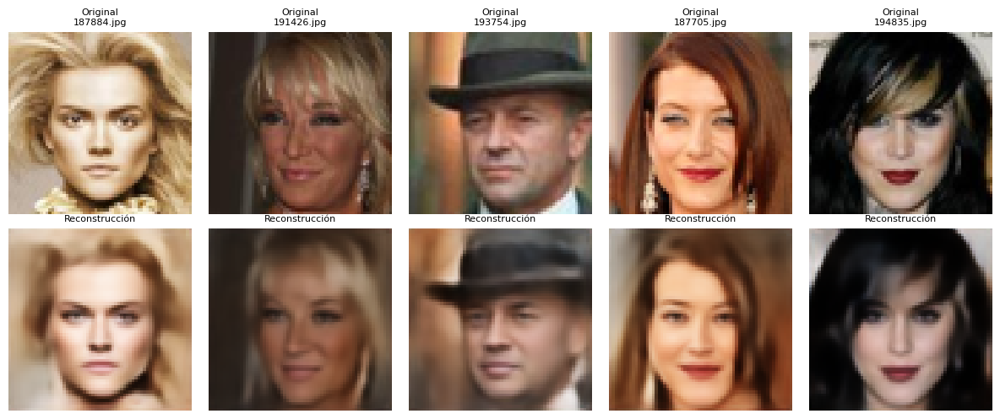

In [12]:
test_indices = sample_rng.choice(len(x_test), size=5, replace=False)
test_reconstructions = autoencoder.predict(x_test[test_indices], verbose=0)
comparison = np.concatenate([x_test[test_indices], test_reconstructions], axis=0)
titles = [f"Original\n{ids_test[i]}" for i in test_indices] + ["Reconstrucción"] * len(test_indices)
show_images(comparison, titles, cols=5, figsize=(12, 5))

Mejor época según val_loss: 30


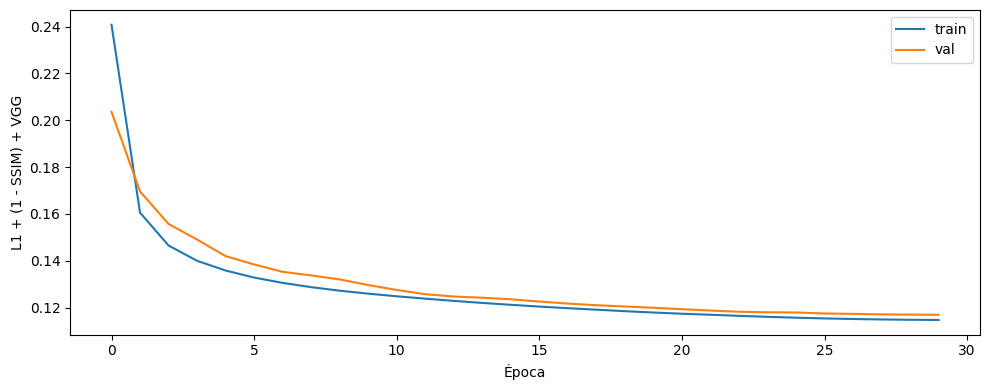

In [13]:
if hasattr(history_ae, "history") and "val_loss" in history_ae.history:
    best_epoch = int(np.argmin(history_ae.history["val_loss"])) + 1
    print(f"Mejor época según val_loss: {best_epoch}")
    plt.figure(figsize=(10, 4))
    plt.plot(history_ae.history["loss"], label="train")
    plt.plot(history_ae.history["val_loss"], label="val")
    plt.xlabel("Época")
    plt.ylabel("L1 + (1 - SSIM) + VGG")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
# FID de reconstrucciones y preparación para el FID del morphing
# El FID compara distribuciones de imágenes; por eso se usa un conjunto de test.
FID_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FID_REAL_SAMPLES = min(1000, len(x_test))
FID_BATCH_SIZE = 32


def prepare_images_for_fid(images):
    images = np.asarray(images)
    if images.ndim == 3:
        images = images[..., np.newaxis]
    if images.ndim != 4 or images.shape[-1] not in (1, 3):
        raise ValueError(f"Se espera imágenes con forma (N, H, W, 1|3), no {images.shape}")
    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)
    if images.shape[-1] == 1:
        images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(np.ascontiguousarray(images))


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    generated_images = prepare_images_for_fid(generated_images)
    real_images = prepare_images_for_fid(real_images)
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(FID_DEVICE)
    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(FID_DEVICE), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(FID_DEVICE), real=False)
    return float(fid.compute().item())

In [16]:
fid_reconstruction_images = x_test[:FID_REAL_SAMPLES]
fid_reconstruction_reference = x_test[FID_REAL_SAMPLES:2 * FID_REAL_SAMPLES]
reconstructed_test_images = autoencoder.predict(
    fid_reconstruction_images,
    batch_size=FID_BATCH_SIZE,
    verbose=0,
)
reconstruction_fid = calculate_fid(
    reconstructed_test_images,
    fid_reconstruction_reference,
)
print(f"FID de reconstrucciones ({FID_REAL_SAMPLES} imágenes): {reconstruction_fid:.4f}")

FID de reconstrucciones (1000 imágenes): 60.3660


El fid ha mejorado desde 61.5248 a 60.3660, lo que indica que la atención espacial de CBAM ha ayudado a que el autoencoder reconstruya mejor las caras y elimine ruido de fondo.

---

## **7. FID y morphing mediante interpolación en el espacio latente**

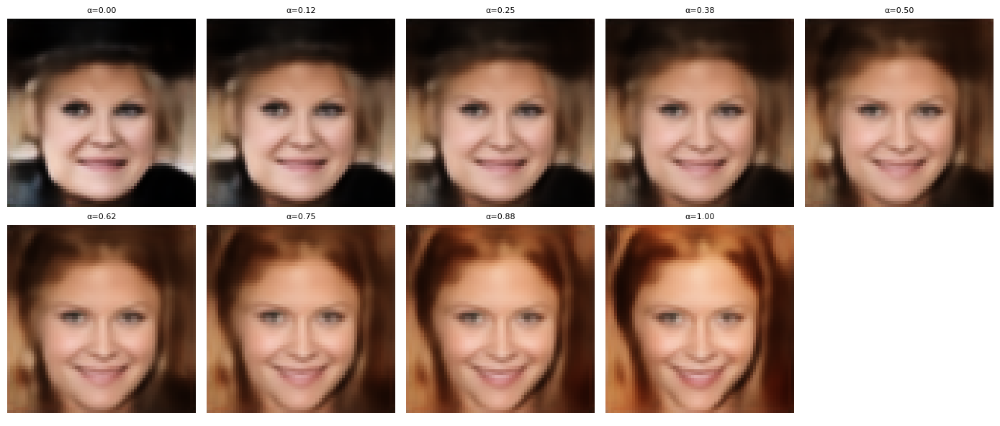

A: 182638.jpg | B: 182640.jpg


In [17]:
def morph_images(image_a, image_b, steps=9):
    if image_a.shape != image_b.shape:
        raise ValueError(f"Las imágenes deben tener la misma forma; recibidas {image_a.shape} y {image_b.shape}")
    z_a = encoder_ae.predict(image_a[None, ...], verbose=0)[0]
    z_b = encoder_ae.predict(image_b[None, ...], verbose=0)[0]
    alphas = np.linspace(0.0, 1.0, steps, dtype=np.float32)
    latent_path = (1.0 - alphas[:, None, None, None]) * z_a + alphas[:, None, None, None] * z_b
    return alphas, decoder_ae.predict(latent_path, verbose=0)

morph_a_index, morph_b_index = 0, 1
alphas, morph_sequence = morph_images(x_test[morph_a_index], x_test[morph_b_index], steps=9)
show_images(
    morph_sequence,
    [f"α={alpha:.2f}" for alpha in alphas],
    cols=5,
    figsize=(14, 6),
)
print(f"A: {ids_test[morph_a_index]} | B: {ids_test[morph_b_index]}")

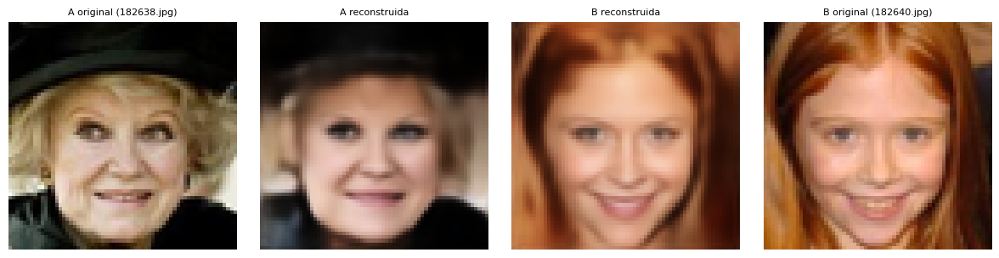

In [18]:
# Comparación de extremos: original frente a reconstrucción usada en la interpolación.
endpoints = np.stack([
    x_test[morph_a_index], morph_sequence[0],
    morph_sequence[-1], x_test[morph_b_index],
])
show_images(
    endpoints,
    [f"A original ({ids_test[morph_a_index]})", "A reconstruida", "B reconstruida", f"B original ({ids_test[morph_b_index]})"],
    cols=4,
    figsize=(12, 3),
)

---

## **8. Secuencia visual y GIF del morphing**

Generamos el GIF de `80` fotogramas en `gif/fusion_mejora2_cbam256_morphing.gif` para comparar visualmente la nitidez del rostro frente al fondo y observar si CBAM reduce el lavado de rasgos respecto a `mejora1.ipynb`.

In [19]:
GIF_PATH = PROCESSED_DIR.parent.parent / "gif" / "fusion_mejora2_cbam256_morphing.gif"
N_FRAMES = 80
FRAME_MS = 50

z_a = encoder_ae.predict(
    x_test[morph_a_index][None, ...],
    verbose=0,
)[0]
z_b = encoder_ae.predict(
    x_test[morph_b_index][None, ...],
    verbose=0,
)[0]

alphas = np.linspace(0.0, 1.0, N_FRAMES, dtype=np.float32)
z_frames = (1.0 - alphas[:, None, None, None]) * z_a + alphas[:, None, None, None] * z_b

decoded = decoder_ae.predict(z_frames, verbose=0)

GIF guardado en '/Users/dani22/Desktop/ProyectoCD/morphing/gif/fusion_mejora2_cbam256_morphing.gif' | 80 fotogramas


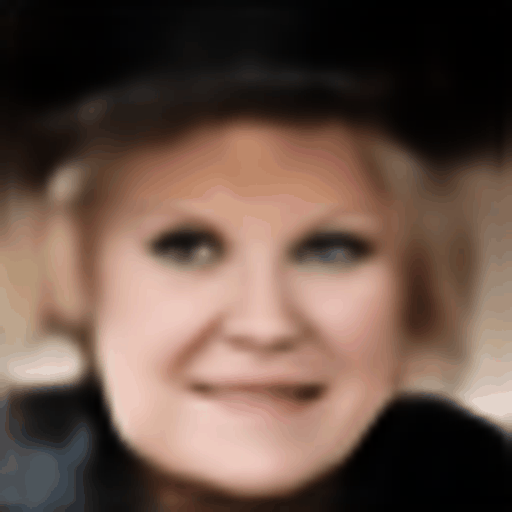

In [20]:
frames = [
    Image.fromarray((np.clip(image, 0, 1) * 255).astype(np.uint8))
    .resize((512, 512), Image.Resampling.BICUBIC)
    for image in decoded
]

gif_path = Path(GIF_PATH).resolve()
gif_path.parent.mkdir(parents=True, exist_ok=True)
if not frames:
    raise RuntimeError("No se generaron fotogramas para el GIF")

frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=FRAME_MS,
    loop=0,
)

print(f"GIF guardado en '{gif_path}' | {len(frames)} fotogramas")
display(IPyImage(filename=str(gif_path)))

---

## **9. Decisiones de diseño y siguiente paso (`mejora3.ipynb`)**

- **Aislamiento experimental:** mantenemos el *Spatial Bottleneck* (`4x4x16`) de `mejora1.ipynb`, la misma pérdida y el mismo entrenamiento, añadiendo únicamente bloques **CBAM** en `16x16` y `8x8`.
- **Resultados:** Hemos obtenido un punto de mejora en el FID, por lo que esta arquitetura nos ha ayudado a mejorar los resultados.
- **Siguiente paso (`mejora3.ipynb`):** como CBAM sigue siendo una operación local (kernel $7 \times 7$), no coordina rasgos distantes entre sí (simetría de ojos, gafas o iluminación global). En `mejora3.ipynb` probaremos la alternativa complementaria sobre el mismo baseline: **Self-Attention**.